# DATHEON INTERNSHIP – TASK 1

## Multi-Class Benchmark Classification Pipeline

### 1. Objective
To build a supervised machine learning classification pipeline using the Iris dataset and compare Logistic Regression and Decision Tree algorithms.

### 2. Dataset
Iris Flower Dataset (iris.csv)

### 3. Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn

### 4. Project Workflow
1. Load and explore the Iris dataset.
2. Perform exploratory data analysis using pairplots.
3. Split the dataset into 80% training and 20% testing data.
4. Normalize features using StandardScaler.
5. Train Logistic Regression and Decision Tree classifiers.
6. Evaluate models using accuracy, precision, recall and F1-score.
7. Visualize confusion matrices and decision boundaries.

### 5. Expected Outcome
Compare both classification algorithms and identify their performance using evaluation metrics and visualizations.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Dataset Loading and Inspection

The Iris dataset is loaded using the Pandas library. It contains 150 flower samples with four numerical features and one target column called species.

The dataset is inspected to understand its structure, feature names, and dimensions.

In [ ]:
df = pd.read_csv("iris.csv")
display(df.head())
print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset Shape: (150, 5)
Columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the dataset, identify missing values, examine statistical properties, and analyse the distribution of different flower species.

### 3.1 Dataset Information and Missing Value Analysis

In [ ]:
print("Dataset Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Records:")
print(df.duplicated().sum())
print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate Records:
1

Statistical Summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### 3.3 Handling Duplicate Records

Duplicate records are identified and removed to maintain data quality and prevent repeated observations from affecting model training.

In [ ]:
print("Before removing duplicates:", df.shape)
df = df.drop_duplicates()
print("After removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Before removing duplicates: (150, 5)
After removing duplicates: (149, 5)
Remaining duplicates: 0


### 3.4 Species Distribution Analysis

The distribution of Iris flower species is analysed to understand the number of samples belonging to each class.

species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64


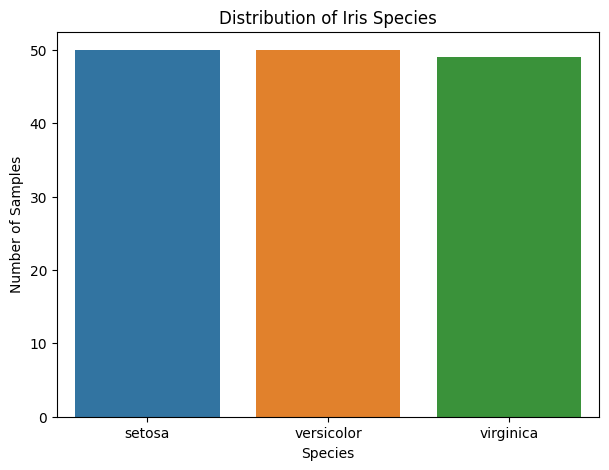

In [ ]:
print(df["species"].value_counts())
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="species", hue="species", legend=False)
plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.show()

### 3.5 Pairplot Visualization

A pairplot is used to visualize the relationships between different numerical features of the Iris dataset. It helps identify patterns and differences among the three flower species.

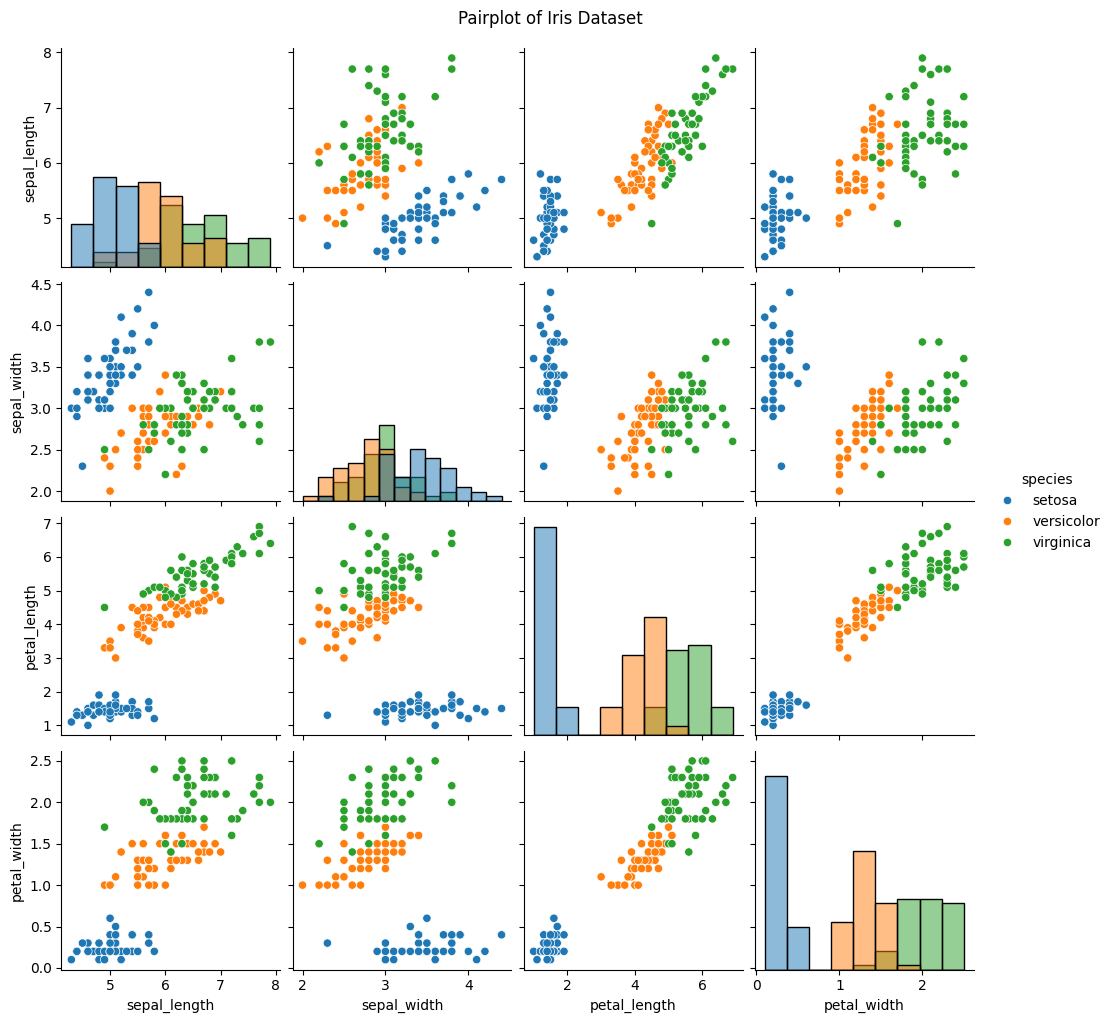

In [ ]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)
plt.suptitle("Pairplot of Iris Dataset", y=1.02)
plt.show()

## 4. Data Preprocessing

Data preprocessing is performed to prepare the dataset for machine learning. The input features and target variable are separated before splitting the dataset into training and testing subsets.

### 4.1 Feature Selection

In [ ]:
X = df.drop("species", axis=1)
y = df["species"]
print("Input Features:")
display(X.head())
print("\nTarget Variable:")
display(y.head())

Input Features:


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target Variable:


0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object

### 4.2 Train-Test Split

The dataset is divided into 80% training data and 20% testing data using train_test_split().

Stratified sampling is applied to maintain the proportion of each Iris species in both datasets.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (119, 4)
Testing Features: (30, 4)

Training Target: (119,)
Testing Target: (30,)


### 4.3 Feature Scaling using StandardScaler

StandardScaler is used to standardize numerical features by transforming them to have a mean of approximately 0 and a standard deviation of 1.

This helps Logistic Regression perform effectively because the input features have different numerical ranges.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)
print("\nScaled Training Data:")
print(X_train_scaled[:5])

Training data shape: (119, 4)
Testing data shape: (30, 4)

Scaled Training Data:
[[-1.50158712  0.7690314  -1.33909259 -1.17973677]
 [ 0.63982407 -0.58674247  1.04183404  1.1863645 ]
 [-0.19294695 -0.13481785  0.24819183  0.00331387]
 [-0.90675068  1.67288064 -1.05564894 -1.0482867 ]
 [-1.26365254  0.09114446 -1.22571513 -1.31118684]]


## 5. Model Training and Classification

Two supervised machine learning algorithms are trained and evaluated to classify Iris flower species.

### 5.1 Logistic Regression

Logistic Regression is a supervised classification algorithm that predicts the probability of a sample belonging to different classes. It is trained using the standardized Iris features.

In [ ]:
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)
y_pred_log = log_model.predict(X_test_scaled)
print("Logistic Regression Model Trained Successfully!")
print("\nActual Values:")
print(y_test.values[:10])
print("\nPredicted Values:")
print(y_pred_log[:10])

Logistic Regression Model Trained Successfully!

Actual Values:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica']

Predicted Values:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica']


### 5.2 Decision Tree Classifier

Decision Tree is a supervised machine learning algorithm that classifies data using a tree-like structure of decision rules. It learns patterns from the training dataset and predicts the species of new samples.

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)
y_pred_dt = dt_model.predict(X_test_scaled)
print("Decision Tree Model Trained Successfully!")
print("\nActual Values:")
print(y_test.values[:10])
print("\nPredicted Values:")
print(y_pred_dt[:10])

Decision Tree Model Trained Successfully!

Actual Values:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica']

Predicted Values:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica']


## 6. Model Evaluation and Performance Benchmarking

Both classification models are evaluated using accuracy, precision, recall, and F1-score.

These metrics help compare the performance of Logistic Regression and Decision Tree classifiers.

### 6.1 Evaluation Metrics

In [ ]:
models_predictions = {
    "Logistic Regression": y_pred_log,
    "Decision Tree": y_pred_dt
}
results = []
for model_name, predictions in models_predictions.items():

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, average="macro")
    recall = recall_score(y_test, predictions, average="macro")
    f1 = f1_score(y_test, predictions, average="macro")

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


### 6.2 Classification Report

The classification report provides precision, recall, F1-score, and support for each Iris species separately.

In [ ]:
print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_log))
print("DECISION TREE")
print(classification_report(y_test, y_pred_dt))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

DECISION TREE
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## 7. Confusion Matrix Visualization

A confusion matrix is used to evaluate the classification performance of each model by comparing actual and predicted class labels.

The heatmap helps visualize correctly and incorrectly classified samples for each Iris species.

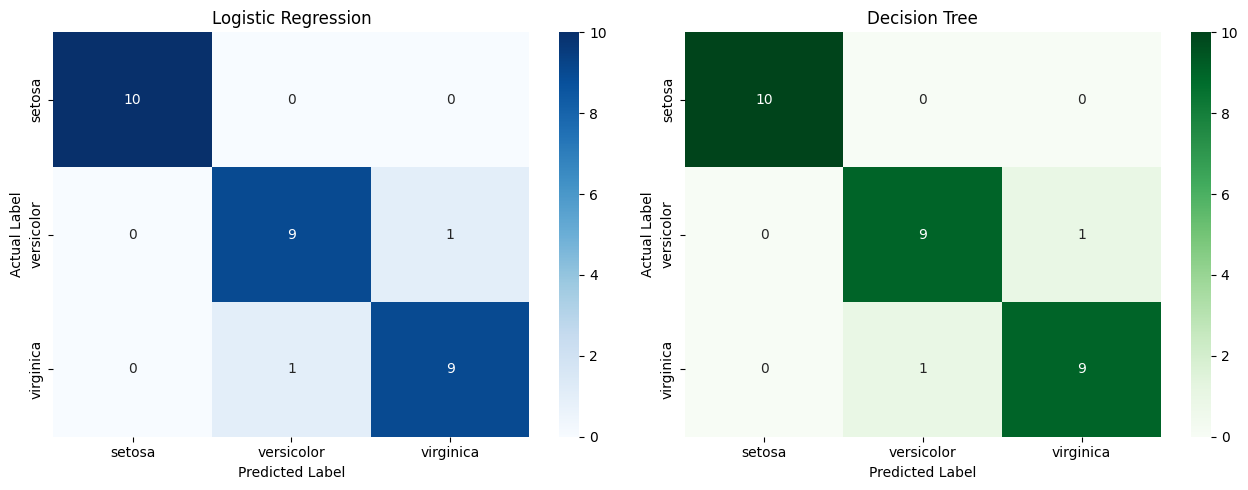

In [ ]:
cm_log = confusion_matrix(y_test, y_pred_log)
cm_dt = confusion_matrix(y_test, y_pred_dt)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(
    cm_log,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=log_model.classes_,
    yticklabels=log_model.classes_,
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_,
    ax=axes[1]
)
axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")
plt.tight_layout()
plt.show()

## 8. Model Performance Comparison

The performance of Logistic Regression and Decision Tree classifiers is compared using accuracy, precision, recall, and F1-score.

A bar chart is generated to visualize the evaluation results and identify the better-performing classification model.

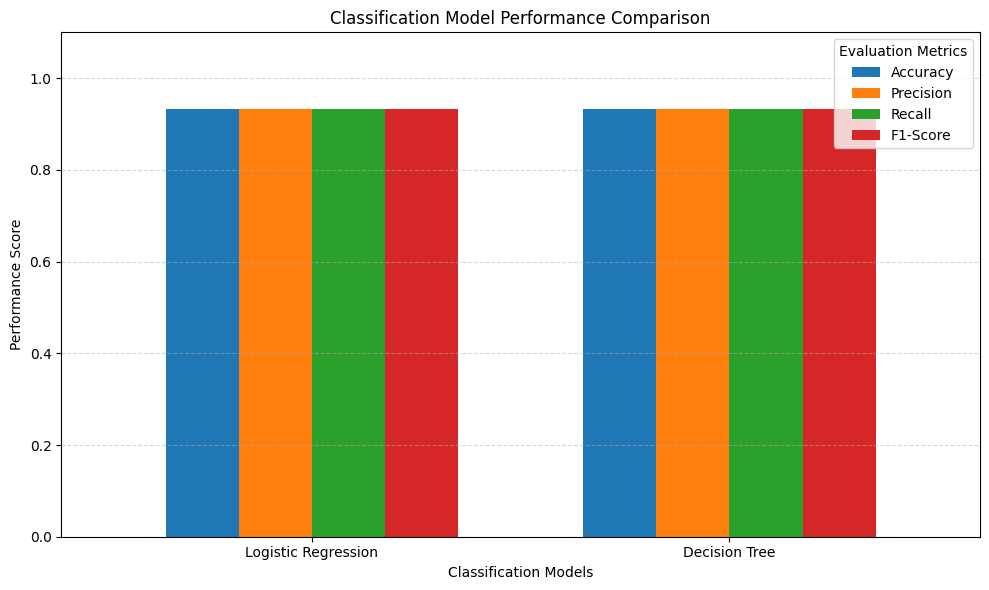

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
comparison = results_df.set_index("Model")
comparison[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)
plt.title("Classification Model Performance Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 9. Decision Boundary Visualization

Decision boundary visualization is used to understand how classification algorithms separate different Iris species.

Petal length and petal width are selected as the two input features to create a two-dimensional visualization.

Both Logistic Regression and Decision Tree decision boundaries are plotted for comparison.

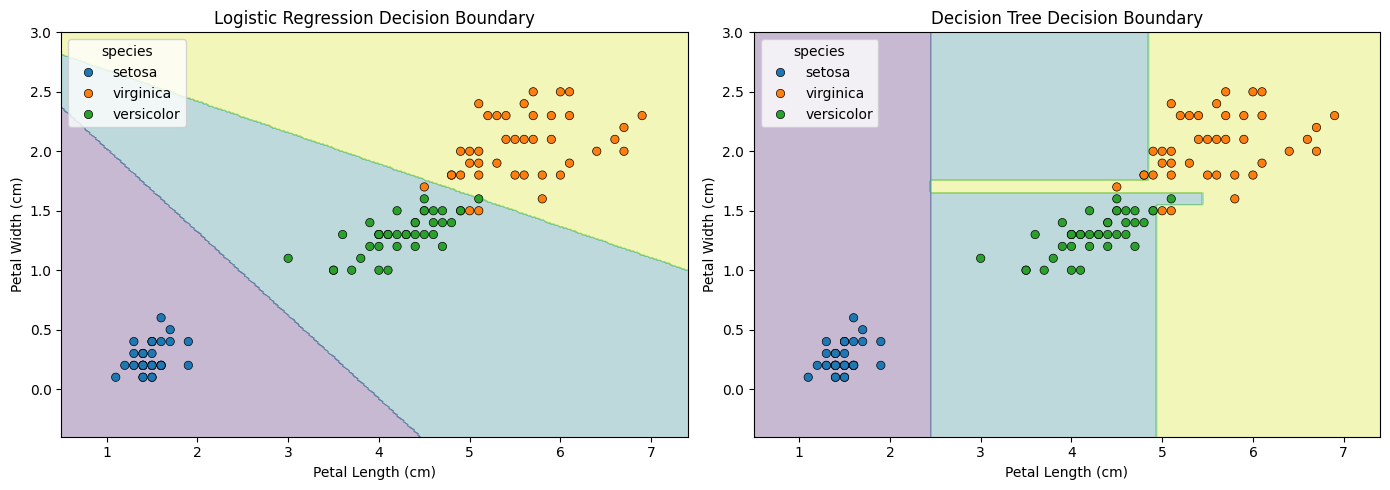

In [ ]:
from sklearn.pipeline import Pipeline
X_2d = df[["petal_length", "petal_width"]]
y_2d = df["species"]
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.20,
    random_state=42,
    stratify=y_2d
)
boundary_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(random_state=42))
    ])
}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, boundary_models.items()):

    model.fit(X_train_2d, y_train_2d)

    x_min, x_max = X_2d["petal_length"].min() - 0.5, X_2d["petal_length"].max() + 0.5
    y_min, y_max = X_2d["petal_width"].min() - 0.5, X_2d["petal_width"].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = pd.DataFrame({
        "petal_length": xx.ravel(),
        "petal_width": yy.ravel()
    })

    Z = model.predict(grid)
    Z = pd.factorize(Z, sort=True)[0].reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

    sns.scatterplot(
        data=pd.concat([X_train_2d, y_train_2d.rename("species")], axis=1),
        x="petal_length",
        y="petal_width",
        hue="species",
        ax=ax,
        edgecolor="black"
    )

    ax.set_title(name + " Decision Boundary")
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")

plt.tight_layout()
plt.show()

## 10. Conclusion

The Multi-Class Benchmark Classification Pipeline was successfully implemented using the Iris dataset.

Two supervised machine learning algorithms, Logistic Regression and Decision Tree, were trained and evaluated.

The dataset was explored, cleaned, and standardized using StandardScaler. An 80/20 train-test split was used for model evaluation.

Both models were evaluated using accuracy, precision, recall, and F1-score. Confusion matrices and decision boundary visualizations were generated to understand their classification performance.

The results demonstrate that both algorithms can effectively classify Iris flower species.

This project provides practical experience in data preprocessing, supervised machine learning, model evaluation, and data visualization using Python and Scikit-learn.

In [ ]:
print("DATHEON INTERNSHIP - TASK 1")
print("FINAL MODEL PERFORMANCE")
print("-" * 50)
display(results_df.round(4))

best_model = results_df.loc[
    results_df["Accuracy"].idxmax(), "Model"
]

print("\nBest Performing Model:", best_model)
print("Dataset Used: Iris Dataset")
print("Total Samples:", len(df))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

DATHEON INTERNSHIP - TASK 1
FINAL MODEL PERFORMANCE
--------------------------------------------------


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333



Best Performing Model: Logistic Regression
Dataset Used: Iris Dataset
Total Samples: 149
Training Samples: 119
Testing Samples: 30
